### **👩‍🏫 👩🏿‍🏫 What You’ll learn**

Scrape data from a dynamic webpage (such as a weather forecast, stock prices, or sports statistics site) and create insightful visualizations of the extracted data.

---

### **🛠️ What you will create**

- Web Scraping Script
- Structured Data File
- Data Analysis Notebook

---

### **Daily Challenge: Web Scraping and Data Visualization**

### **Your Task**

### **Instructions**

- Use this webpage: [Tel Aviv - BBC Weather](https://www.bbc.com/weather/293397)
- Scrape the Webpage: Use Python libraries like `Selenium` to interact with the webpage and `BeautifulSoup` to parse the HTML, Extract relevant data such as dates, numerical values, categories, etc., Organize the scraped data into a structured format.
- Data Analysis with `Pandas`:
    - Load your scraped data into a `Pandas` `DataFrame`.
    - Clean and preprocess the data if necessary (handling missing values, type conversion, etc.).
    - Perform basic analysis, such as calculating averages, totals, or trends over time.
- Data Visualization with `Seaborn` and `Matplotlib`:
    - Use `Seaborn` and `Matplotlib` to create visualizations that provide insights into the data.
    - Examples of visualizations can include line plots for trends over time, bar charts for comparing categories, or heatmaps for showing data density.
    - Ensure your visualizations are well-labeled with clear titles, axis labels, and legends where appropriate.
- Document Your Findings:
    - Create a report summarizing your methodology, analysis, and insights from the visualizations.
    - Explain any interesting patterns or insights derived from your data.


## 1. Environment setup

The notebook runs on a Google Colab runtime, which has no Chrome installed. Running plain Selenium here crashed Chrome as soon as it started (`SessionNotCreatedException`), so the scraper uses `google-colab-selenium`. It installs Chrome and chromedriver and starts Chrome with the headless options Colab needs.


In [56]:
%pip install google-colab-selenium

In [57]:
import re
from datetime import date, timedelta
from pathlib import Path

import google_colab_selenium as gs
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from bs4 import BeautifulSoup, Tag
from selenium.webdriver.common.by import By
from selenium.webdriver.support import expected_conditions as EC
from selenium.webdriver.support.ui import WebDriverWait

In [ ]:
URL = "https://www.bbc.com/weather/293397"

RAW_CSV_PATH = Path("tel_aviv_forecast_raw.csv")
CLEAN_CSV_PATH = Path("tel_aviv_forecast_clean.csv")

TEMP_COLUMNS = ["high_temp_c", "low_temp_c"]
WIND_ORDER = ["light", "gentle", "moderate", "fresh", "strong"]

LOW_COLOR = "#2a78d6"
HIGH_COLOR = "#eb6834"
RANGE_COLOR = "#e8e7e2"
BLUE_RAMP = [
    "#cde2fb",
    "#9ec5f4",
    "#6da7ec",
    "#3987e5",
    "#256abf",
    "#184f95",
    "#0d366b",
]

## 2. Scraping the page

Selenium opens the forecast in a headless Chrome, then waits for the day cards to exist before reading the page. The wait uses `presence_of_all_elements_located` rather than visibility: the data only has to be in the HTML for BeautifulSoup, and the 14 days sit in a horizontally scrolling strip, so a visibility check could time out on cards that are scrolled out of view.

Each forecast day is an `<li class="wr-day wr-day--N wr-js-day">` element. The selector uses `wr-day` because all 14 cards share it, while `wr-day--N` matches a single day.


In [59]:
driver = gs.Chrome()
driver.get(URL)
print(driver.title)

<IPython.core.display.Javascript object>

Tel Aviv - BBC Weather


In [60]:
wait = WebDriverWait(driver, 10)
day_card_elements = wait.until(
    EC.presence_of_all_elements_located((By.CLASS_NAME, "wr-day"))
)

print(len(day_card_elements))  # Should result 14.

14


In [61]:
soup = BeautifulSoup(driver.page_source, "html.parser")

day_cards = soup.select(".wr-day")
print(len(day_cards))  # Should result 14.

14


In [62]:
driver.quit()

In [63]:
SCRAPE_DATE = pd.Timestamp.now(tz="Asia/Jerusalem").date()

## 3. Extracting the fields

What DevTools shows inside each day card:

- **Date:** the title holds three versions of the date. `wr-date__long` ("Thursday 29th October") is the only one with the month, which is needed to build real dates once the forecast runs into November. The first card says "Today" and has no `wr-date__long`, so its title comes back as `None`.
- **Temperatures:** the high and low values each hold a °C and a °F number in separate nested elements. Selecting `.wr-value--temperature--c` inside `wr-day-temperature__high-value` / `__low-value` keeps only °C.
- **Description:** `wr-day__details__weather-type-description` holds one sentence combining the weather and the wind.

`extract_text` uses a space as the separator, because the nested date spans otherwise run together as "Thursday29thOctober". The values are kept as raw text here, and all type conversion happens in the cleaning section.


In [64]:
def extract_text(card: Tag, selector: str) -> str | None:
    """
    Return the stripped text of the first element matching a CSS selector inside one day card.

    Args:
        card (Tag): One forecast day card (an <li class="wr-day"> element).
        selector (str): CSS selector to look for inside the card, e.g. ".wr-date__long".

    Returns:
        str | None: The element's text with nested parts joined by spaces, or None if the element isn't found.
    """
    element_found = card.select_one(selector)

    return element_found.get_text(separator=" ", strip=True) if element_found else None

In [65]:
def parse_day_card(card: Tag) -> dict[str, str | None]:
    """
    Extract the raw forecast fields from one BBC Weather day card.

    Args:
        card (Tag): One forecast day card (an <li class="wr-day"> element).

    Returns:
        dict[str, str | None]: The card's raw text values keyed by 'day_title', 'high_temp_c',
            'low_temp_c' and 'description', with None for any field missing from the card.
    """
    return {
        "day_title": extract_text(card, ".wr-date__long"),
        "high_temp_c": extract_text(
            card, ".wr-day-temperature__high-value .wr-value--temperature--c"
        ),
        "low_temp_c": extract_text(
            card, ".wr-day-temperature__low-value .wr-value--temperature--c"
        ),
        "description": extract_text(card, ".wr-day__details__weather-type-description"),
    }

In [66]:
forecast_rows = [parse_day_card(card) for card in day_cards]

print(forecast_rows[0])
print(forecast_rows[1])
print(forecast_rows[13])

{'day_title': None, 'high_temp_c': '26°', 'low_temp_c': '19°', 'description': 'Sunny and a gentle breeze'}
{'day_title': 'Thursday 29th October', 'high_temp_c': '27°', 'low_temp_c': '19°', 'description': 'Sunny and a moderate breeze'}
{'day_title': 'Tuesday 10th November', 'high_temp_c': '21°', 'low_temp_c': '14°', 'description': 'Light rain and a gentle breeze'}


## 4. Raw data file

The raw rows are saved to CSV **before** any cleaning. A forecast changes every few hours, so this snapshot can't be scraped again. Keeping it means the cleaning can always be rerun on the original values.


In [67]:
pd.DataFrame(forecast_rows).to_csv(RAW_CSV_PATH, index=False)
print(f"Saved to {RAW_CSV_PATH.resolve()}")

Saved to /content/tel_aviv_forecast_raw.csv


In [68]:
forecast = pd.read_csv(RAW_CSV_PATH)

In [69]:
forecast.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14 entries, 0 to 13
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   day_title    13 non-null     object
 1   high_temp_c  14 non-null     object
 2   low_temp_c   14 non-null     object
 3   description  14 non-null     object
dtypes: object(4)
memory usage: 580.0+ bytes


In [70]:
forecast["description"].unique()

array(['Sunny and a gentle breeze', 'Sunny and a moderate breeze',
       'Sunny intervals and a gentle breeze',
       'Light rain showers and a moderate breeze',
       'Light rain showers and a gentle breeze',
       'Thundery showers and a gentle breeze',
       'Light rain and a gentle breeze'], dtype=object)

## 5. Cleaning

What the raw data needs, based on the checks above:

- **All 4 columns are `object` (text).** The temperatures read `'27°'`, so the `°` has to go before they can become numbers.
- **`day_title` has 1 missing value out of 14.** It's the "Today" card, so it isn't missing data: it becomes the scrape date. The other columns have no missing values, so nothing needs filling or dropping.
- **The 7 unique descriptions all follow `<weather> and a <strength> breeze`.** Splitting them gives two categorical columns. The split is made **once from the right** (`rsplit`), because the wind phrase is always last and never contains "and", so it stays correct even if a weather type someday contains "and".
- **Wind strength** is reduced to its Beaufort word (gentle, moderate, ...) and stored as an **ordered** category, so sorting and charts follow wind strength instead of alphabetical order.


In [71]:
def parse_forecast_date(title: str | None, scrape_date: date) -> date:
    """
    Convert a BBC forecast day title like 'Thursday 29th October' into a real date.

    Args:
        title (str | None): The scraped wr-date__long text, or None / NaN / 'Today' for the first card.
        scrape_date (date): The date the page was scraped, in Tel Aviv local time.

    Returns:
        date: The calendar date this forecast card refers to.
    """
    if pd.isna(title) or title.strip().lower() == "today":
        return scrape_date

    cleaned = re.sub(r"(\d+)\s*(st|nd|rd|th)\b", r"\1", title)
    parsed = pd.to_datetime(
        f"{cleaned} {scrape_date.year}", format="%A %d %B %Y"
    ).date()

    if parsed < scrape_date:
        parsed = parsed.replace(year=scrape_date.year + 1)

    return parsed

In [72]:
forecast["date"] = pd.to_datetime(
    [parse_forecast_date(title, SCRAPE_DATE) for title in forecast["day_title"]]
)

In [ ]:
day_gaps = forecast["date"].diff().dropna()

print(
    f"From {forecast['date'].min():%a %d %b %Y} to {forecast['date'].max():%a %d %b %Y}"
)
print(f"Consecutive days with no gaps: {(day_gaps == timedelta(days=1)).all()}")

From Wed 28 Oct 2026 to Tue 10 Nov 2026
Consecutive days with no gaps: True


In [74]:
def clean_temperature(raw_temps: pd.Series) -> pd.Series:
    """
    Strip the degree sign from scraped temperature text and convert it to whole numbers.

    Args:
        raw_temps (pd.Series): Temperatures as text, e.g. '27°'.

    Returns:
        pd.Series: The same temperatures as nullable integers (Int64), with <NA> where a value was missing.
    """
    return pd.to_numeric(raw_temps.str.replace("°", "", regex=False)).astype("Int64")

In [75]:
for column in TEMP_COLUMNS:
    forecast[column] = clean_temperature(forecast[column])

In [76]:
forecast["temp_range_c"] = forecast["high_temp_c"] - forecast["low_temp_c"]

In [ ]:
forecast[["weather", "wind"]] = forecast["description"].str.rsplit(
    " and ", n=1, expand=True
)

In [78]:
forecast["wind"] = pd.Categorical(
    forecast["wind"].str.extract(r"^(?:a\s+)?(\w+)", expand=False),
    categories=WIND_ORDER,
    ordered=True,
)

In [79]:
forecast = forecast[
    ["date", "weather", "wind", "high_temp_c", "low_temp_c", "temp_range_c"]
].copy()

In [80]:
forecast.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14 entries, 0 to 13
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   date          14 non-null     datetime64[ns]
 1   weather       14 non-null     object        
 2   wind          14 non-null     category      
 3   high_temp_c   14 non-null     Int64         
 4   low_temp_c    14 non-null     Int64         
 5   temp_range_c  14 non-null     Int64         
dtypes: Int64(3), category(1), datetime64[ns](1), object(1)
memory usage: 960.0+ bytes


In [81]:
forecast.isna().sum()

,0
date,0
weather,0
wind,0
high_temp_c,0
low_temp_c,0
temp_range_c,0


In [82]:
forecast.to_csv(CLEAN_CSV_PATH, index=False)
print(f"Saved to {CLEAN_CSV_PATH.resolve()}")

Saved to /content/tel_aviv_forecast_clean.csv


## 6. Analysis

The analysis covers three areas:

- **Overall temperatures:** summary statistics for the highs, lows and daily range.
- **Trend over time:** a week 1 vs week 2 comparison and a fitted °C-per-day slope for highs and lows.
- **Categories:** how many days fall under each weather type and wind strength, with the average temperatures for each.


In [ ]:
forecast[["high_temp_c", "low_temp_c", "temp_range_c"]].astype(float).describe().round(
    1
)

,high_temp_c,low_temp_c,temp_range_c
count,14.0,14.0,14.0
mean,24.3,16.7,7.6
std,2.0,1.6,0.9
min,21.0,14.0,7.0
25%,22.2,15.2,7.0
50%,24.5,17.0,7.0
75%,26.0,17.8,8.0
max,27.0,19.0,9.0


In [84]:
forecast["forecast_week"] = (forecast["date"] - forecast["date"].min()).dt.days // 7 + 1

In [85]:
forecast.groupby("forecast_week")[TEMP_COLUMNS + ["temp_range_c"]].mean().round(1)

,high_temp_c,low_temp_c,temp_range_c
forecast_week,,,
1,26.0,17.9,8.1
2,22.6,15.6,7.0


In [86]:
def daily_trend(dates: pd.Series, values: pd.Series) -> float:
    """
    Fit a straight line through a series of values over time and return its slope.

    Args:
        dates (pd.Series): The forecast dates (datetime64).
        values (pd.Series): The values to fit, one per date.

    Returns:
        float: The average change per day, in the values' units.
    """
    days_from_start = (dates - dates.min()).dt.days
    slope, _ = np.polyfit(days_from_start, values.astype(float), 1)

    return slope

In [87]:
for column in TEMP_COLUMNS:
    slope = daily_trend(forecast["date"], forecast[column])
    print(f"{column}: {slope:+.2f} °C per day ({slope * 13:+.1f} °C over the 14 days)")

high_temp_c: -0.43 °C per day (-5.5 °C over the 14 days)
low_temp_c: -0.33 °C per day (-4.3 °C over the 14 days)


In [88]:
def category_summary(df: pd.DataFrame, column: str) -> pd.DataFrame:
    """
    Count the forecast days in each category of a column, with their average temperatures.

    Args:
        df (pd.DataFrame): The cleaned forecast.
        column (str): The categorical column to group by, e.g. 'weather' or 'wind'.

    Returns:
        pd.DataFrame: One row per category with the number of days and the average high and low in °C.
    """
    return (
        df.groupby(column, observed=True)
        .agg(
            days=("date", "size"),
            avg_high_c=("high_temp_c", "mean"),
            avg_low_c=("low_temp_c", "mean"),
        )
        .astype({"avg_high_c": float, "avg_low_c": float})
        .round(1)
        .sort_values("days", ascending=False)
    )

In [89]:
category_summary(forecast, "weather")

,days,avg_high_c,avg_low_c
weather,,,
Sunny,7,25.9,18.0
Light rain showers,3,23.0,16.0
Light rain,2,21.5,14.5
Sunny intervals,1,25.0,16.0
Thundery showers,1,22.0,15.0


In [90]:
category_summary(forecast, "wind")

,days,avg_high_c,avg_low_c
wind,,,
gentle,12,24.1,16.5
moderate,2,25.5,18.0


In [91]:
key_days = {
    "Warmest day": forecast.loc[forecast["high_temp_c"].idxmax()],
    "Coolest night": forecast.loc[forecast["low_temp_c"].idxmin()],
    "Widest daily range": forecast.loc[forecast["temp_range_c"].idxmax()],
}

for label, day in key_days.items():
    print(
        f"{label}: {day['date']:%a %d %b} | high {day['high_temp_c']}°C, "
        f"low {day['low_temp_c']}°C, range {day['temp_range_c']}°C | {day['weather']}"
    )

Warmest day: Thu 29 Oct | high 27°C, low 19°C, range 8°C | Sunny
Coolest night: Tue 10 Nov | high 21°C, low 14°C, range 7°C | Light rain
Widest daily range: Fri 30 Oct | high 25°C, low 16°C, range 9°C | Sunny intervals


## 7. Visualizations

Four charts, each chosen for one question:

1. **Line chart:** how do the highs and lows change over the 14 days? Dates are continuous, so a line shows the trend, and the shaded band between the lines shows the daily range.
2. **Horizontal bar chart:** which weather types come up most often? Weather types are categories without an order, so bars sorted by count are the clearest comparison.
3. **Strip chart:** are some weather types warmer than others? With only 14 days, every day is drawn as its own dot instead of being summarised in a box plot.
4. **Heatmap:** which weather and wind combinations occur together? It shows the number of days in each combination.


In [92]:
sns.set_theme(style="white", rc={"figure.dpi": 110, "axes.titleweight": "bold"})

In [ ]:
def label_chart(
    ax: plt.Axes, title: str, xlabel: str, ylabel: str, grid_axis: str = "y"
) -> None:
    """
    Apply a left-aligned title, axis labels, a light grid and clean spines to a chart.

    Args:
        ax (plt.Axes): The chart to label.
        title (str): The chart title.
        xlabel (str): The x-axis label.
        ylabel (str): The y-axis label.
        grid_axis (str, optional): Which axis gets gridlines ('x', 'y' or 'both'). Defaults to "y".

    Returns:
        None: The chart is modified in place.
    """
    ax.set_title(title, loc="left", pad=12)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.grid(axis=grid_axis, alpha=0.3)
    ax.set_axisbelow(True)
    sns.despine(ax=ax)

In [ ]:
temps_long = forecast.melt(
    id_vars="date", value_vars=TEMP_COLUMNS, var_name="measure", value_name="temp_c"
)
temps_long["measure"] = temps_long["measure"].map(
    {"high_temp_c": "High", "low_temp_c": "Low"}
)
temps_long["temp_c"] = temps_long["temp_c"].astype(float)

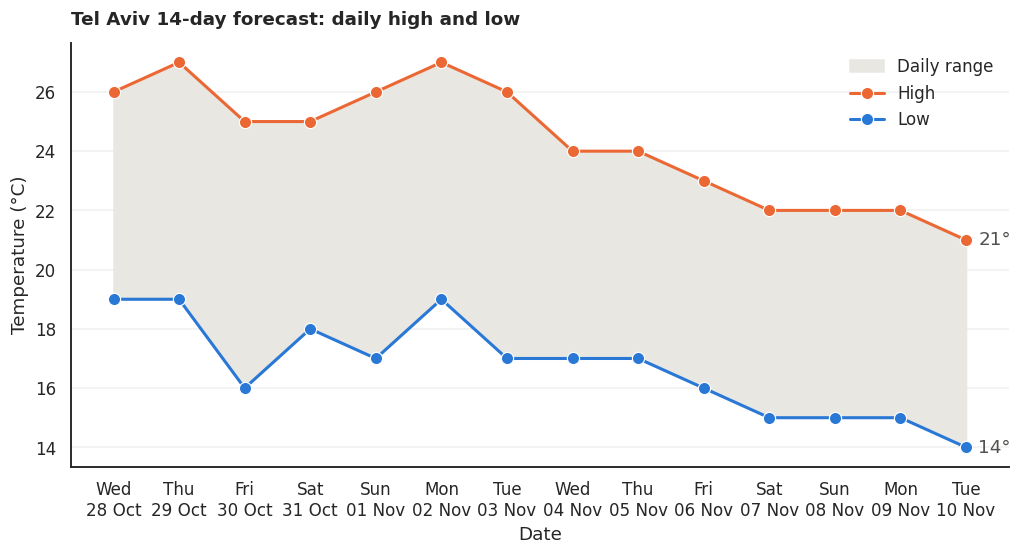

In [ ]:
fig, ax = plt.subplots(figsize=(11, 5))

ax.fill_between(
    forecast["date"],
    forecast["low_temp_c"].astype(float),
    forecast["high_temp_c"].astype(float),
    color=RANGE_COLOR,
    label="Daily range",
)
sns.lineplot(
    data=temps_long,
    x="date",
    y="temp_c",
    hue="measure",
    palette={"High": HIGH_COLOR, "Low": LOW_COLOR},
    marker="o",
    markersize=8,
    linewidth=2,
    ax=ax,
)

last_day = forecast.iloc[-1]
for column, color in [("high_temp_c", HIGH_COLOR), ("low_temp_c", LOW_COLOR)]:
    ax.annotate(
        f"{last_day[column]}°",
        (last_day["date"], last_day[column]),
        xytext=(8, 0),
        textcoords="offset points",
        va="center",
        color="#52514e",
    )

ax.xaxis.set_major_locator(mdates.DayLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%a\n%d %b"))
ax.legend(title=None, frameon=False, loc="upper right")
label_chart(
    ax, "Tel Aviv 14-day forecast: daily high and low", "Date", "Temperature (°C)"
)
plt.show()

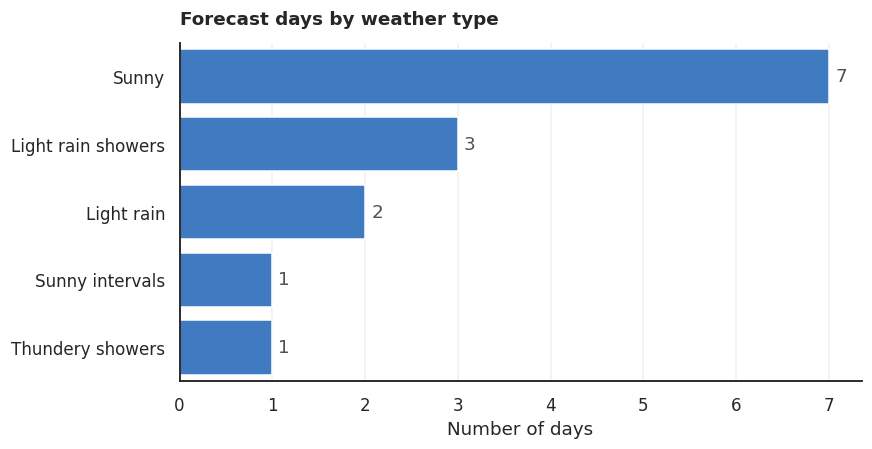

In [96]:
weather_counts = forecast["weather"].value_counts()

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x=weather_counts.values, y=weather_counts.index, color=LOW_COLOR, ax=ax)
ax.bar_label(ax.containers[0], padding=4, color="#52514e")
label_chart(ax, "Forecast days by weather type", "Number of days", "", grid_axis="x")
plt.show()

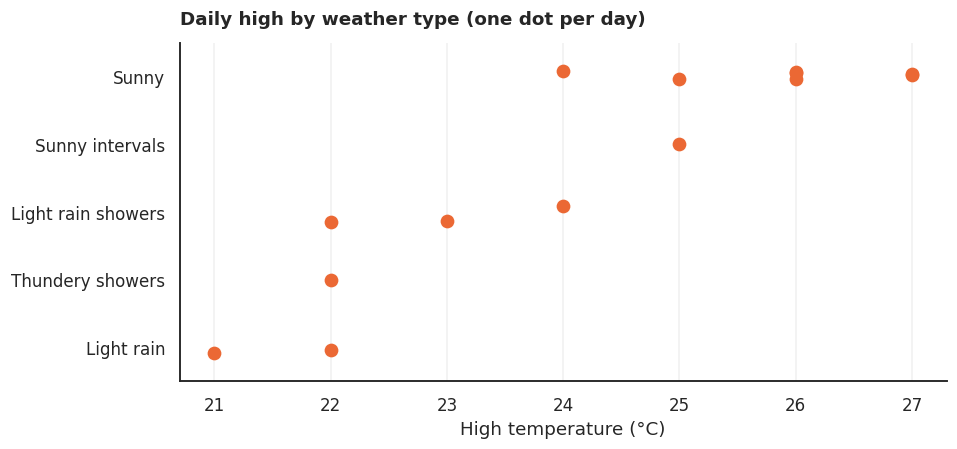

In [ ]:
weather_by_high = (
    forecast.groupby("weather")["high_temp_c"]
    .mean()
    .astype(float)
    .sort_values(ascending=False)
)

fig, ax = plt.subplots(figsize=(9, 4))
sns.stripplot(
    data=forecast.astype({"high_temp_c": float}),
    x="high_temp_c",
    y="weather",
    order=weather_by_high.index,
    color=HIGH_COLOR,
    size=9,
    jitter=0.15,
    ax=ax,
)
label_chart(
    ax,
    "Daily high by weather type (one dot per day)",
    "High temperature (°C)",
    "",
    grid_axis="x",
)
plt.show()

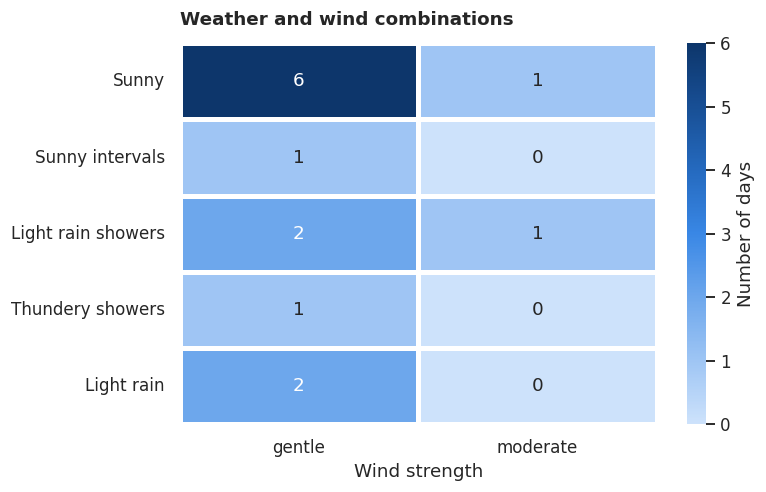

In [ ]:
weather_wind = pd.crosstab(forecast["weather"], forecast["wind"])
weather_wind = weather_wind.loc[weather_by_high.index, weather_wind.sum() > 0]

fig, ax = plt.subplots(figsize=(7, 4.5))
sns.heatmap(
    weather_wind,
    annot=True,
    fmt="d",
    cmap=sns.blend_palette(BLUE_RAMP, as_cmap=True),
    linewidths=2,
    linecolor="white",
    cbar_kws={
        "label": "Number of days",
        "ticks": range(weather_wind.to_numpy().max() + 1),
    },
    ax=ax,
)
ax.set_title("Weather and wind combinations", loc="left", pad=12)
ax.set_xlabel("Wind strength")
ax.set_ylabel("")
plt.show()

## 8. Report

### Methodology

1. **Scraping:** Selenium (through `google-colab-selenium` on Colab) loaded the [BBC Weather page for Tel Aviv](https://www.bbc.com/weather/293397) in headless Chrome and waited for all 14 `wr-day` cards to be present. The rendered HTML was then parsed with BeautifulSoup.
2. **Extraction:** each card was parsed into a row of raw text: the long date title, the °C high and low, and the weather description. Missing elements became `None` instead of stopping the scrape.
3. **Storage:** the raw rows were saved to `tel_aviv_forecast_raw.csv` before any changes, and the cleaned table to `tel_aviv_forecast_clean.csv`.
4. **Cleaning:** date titles were converted to real dates (the "Today" card became the scrape date in Tel Aviv time), `°` was removed and the temperatures converted to integers, the description was split into weather and wind, and wind strength became an ordered category. A daily range column (high minus low) was added.
5. **Analysis:** summary statistics, a week 1 vs week 2 comparison, a fitted trend line for the highs and lows, and per-category day counts with average temperatures.

### Insights

- **The forecast cools down over the two weeks.** The first two days (28 and 29 October) are sunny at 27°C / 19°C, and the last day (Tuesday 10 November) is light rain at 21°C / 14°C: 6°C cooler by day and 5°C cooler at night. The week 1 vs week 2 table and the fitted slopes measure how steady that decline is across all 14 days.
- **Dry weather turns wet.** The forecast starts with sunny days and includes light rain, light rain showers and thundery showers. In the line chart, the rainy days match the lower highs, and the strip chart shows whether rainy weather types have lower daily highs than sunny ones.
- **The wind stays mild.** Every one of the 14 days is a gentle or moderate breeze (Beaufort force 3 to 4), with no stronger winds, so temperature and rain are what change across the period, not wind.

### Limitations

- This is **one snapshot of a forecast**, not observed weather. Rerunning the notebook scrapes a newer forecast with different values.
- Fourteen rows are enough to describe the forecast, not to draw statistical conclusions. The category averages for weather types that appear on only one or two days are especially uncertain.
